I1 (220, 220) 21.0 240.0
I2 (256, 256) 0.0 255.0


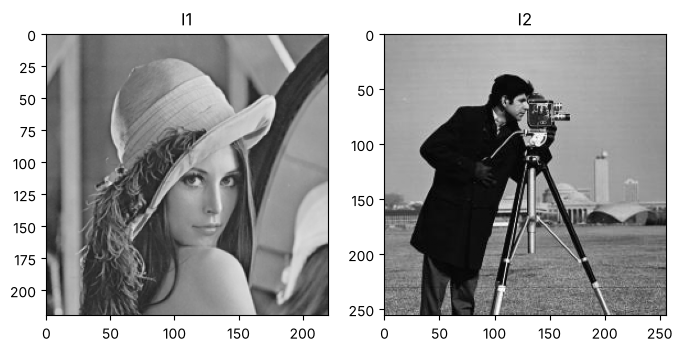

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import restoration as r

rng = np.random.default_rng(0)      # fixed seed, so the noise is the same every run
images = r.load_images("img_restoration.mat")

for name in images:
    print(name, images[name].shape, images[name].min(), images[name].max())

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(images["I1"], cmap="gray", vmin=0, vmax=255)
ax[0].set_title("I1")
ax[1].imshow(images["I2"], cmap="gray", vmin=0, vmax=255)
ax[1].set_title("I2")
plt.show()

In [2]:
# Helper: show a row of images with their PSNR
def show(f, results):
    fig, ax = plt.subplots(1, len(results), figsize=(4 * len(results), 4))
    for i, title in enumerate(results):
        img = results[title]
        ax[i].imshow(np.clip(img, 0, 255), cmap="gray", vmin=0, vmax=255)
        ax[i].set_title(f"{title}\nPSNR = {r.psnr(f, img):.1f} dB")
        ax[i].axis("off")
    plt.show()

## 1. Motion-blur kernel and its transfer function
A straight line of `L` pixels at angle `ANGLE`. $|H(u,v)|$ has (near-)zeros along lines perpendicular to the motion direction. At those frequencies the image information is lost, and the inverse filter would divide by almost zero.

smallest |H| = 1.9887277958885373e-18
fraction of frequencies with |H| < 0.01 = 0.03950413223140496


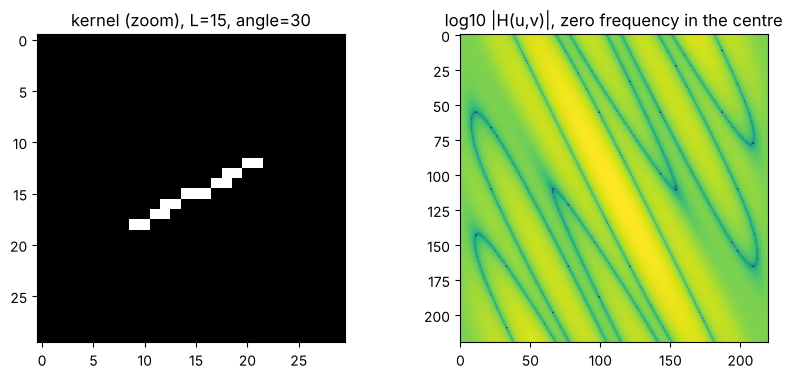

In [3]:
L = 15          # blur length in pixels
ANGLE = 30      # blur direction in degrees
SIGMA = 10      # noise standard deviation (0-255 scale)

f = images["I1"]
psf = r.motion_psf(L, ANGLE, f.shape)
H = np.fft.fft2(psf)

print("smallest |H| =", np.abs(H).min())
print("fraction of frequencies with |H| < 0.01 =", np.mean(np.abs(H) < 0.01))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(np.fft.fftshift(psf)[95:125, 95:125], cmap="gray")
ax[0].set_title(f"kernel (zoom), L={L}, angle={ANGLE}")
ax[1].imshow(np.log10(np.abs(np.fft.fftshift(H)) + 1e-6))
ax[1].set_title("log10 |H(u,v)|, zero frequency in the centre")
plt.show()

## 2. The three distortions

/home/user/sdsp-image-restoration/restoration.py:169: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10(255 ** 2 / mse(f, f_hat))


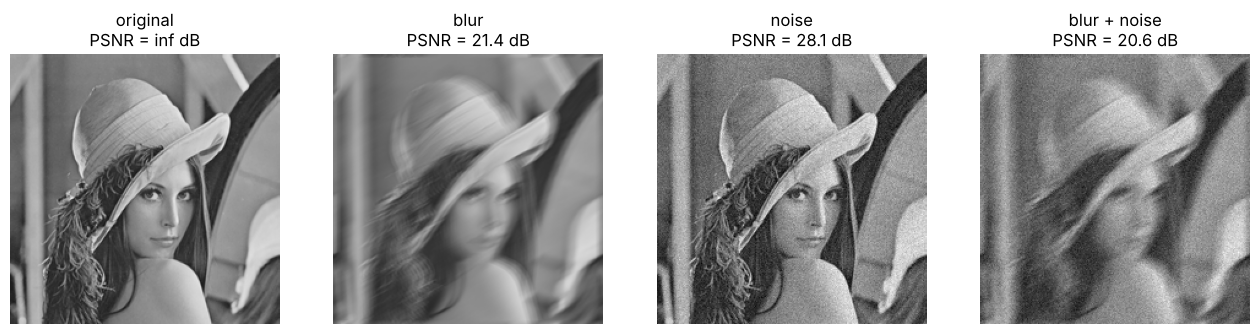

In [4]:
g_blur = r.blur(f, H)
g_noise = r.add_noise(f, SIGMA, rng)
g_both = r.add_noise(r.blur(f, H), SIGMA, rng)

show(f, {"original": f, "blur": g_blur, "noise": g_noise, "blur + noise": g_both})

## 3. Inverse filter
Without noise, the inverse filter gives back the original almost perfectly, **except** where $H$ is exactly zero: for I1 this kernel has a few frequencies with $|H|\approx 10^{-18}$, so even $\varepsilon = 0$ fails (division by zero amplifies rounding errors). A tiny threshold such as $\varepsilon = 0.001$ fixes it. With noise, $\hat F = F + N/H$: the noise is divided by tiny values of $H$ and explodes. A threshold $\varepsilon$ stops that, but the frequencies that are set to zero are lost.

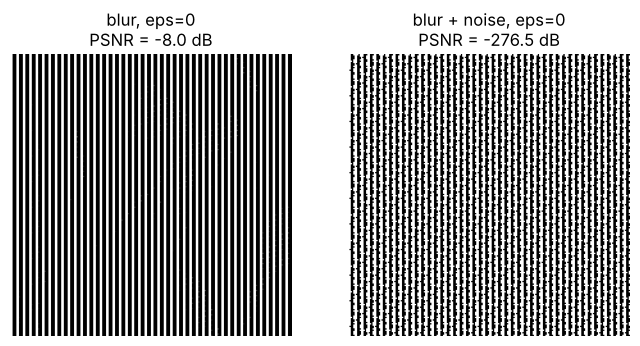

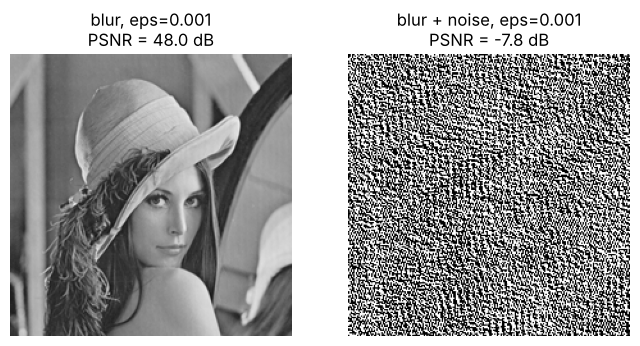

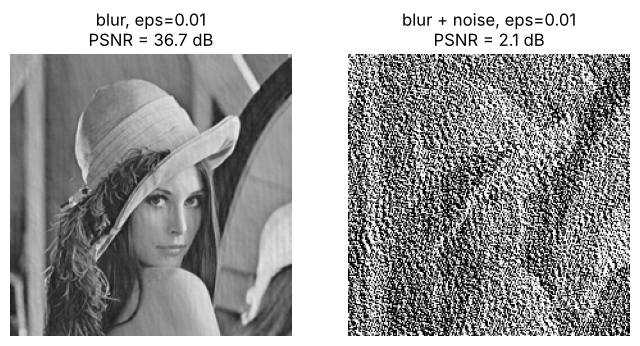

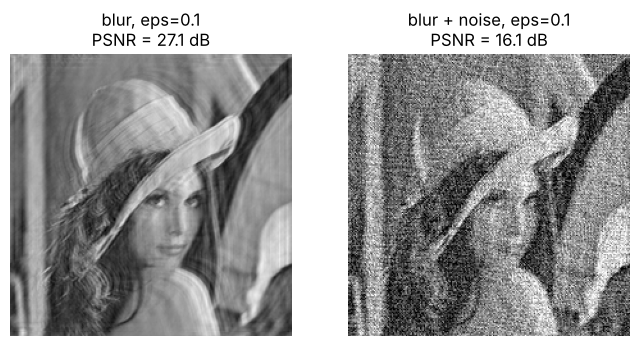

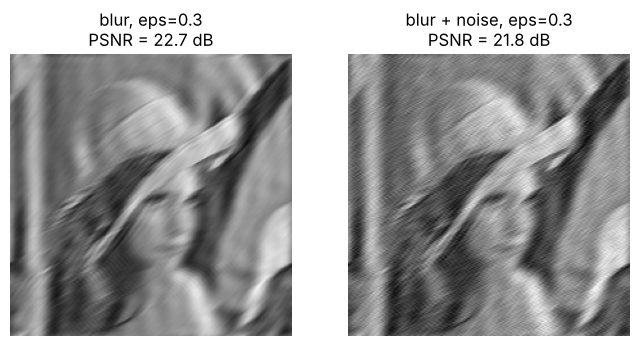

In [5]:
for eps in [0, 0.001, 0.01, 0.1, 0.3]:
    show(f, {f"blur, eps={eps}": r.inverse_filter(g_blur, H, eps),
             f"blur + noise, eps={eps}": r.inverse_filter(g_both, H, eps)})

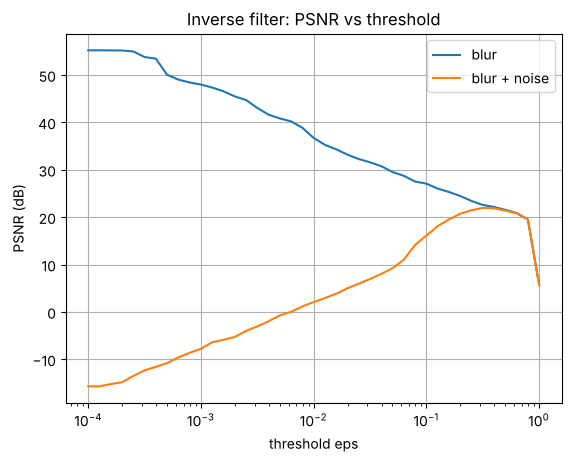

In [6]:
eps_values = np.logspace(-4, 0, 41)
psnr_blur = []
psnr_both = []
for eps in eps_values:
    psnr_blur.append(r.psnr(f, r.inverse_filter(g_blur, H, eps)))
    psnr_both.append(r.psnr(f, r.inverse_filter(g_both, H, eps)))

plt.semilogx(eps_values, psnr_blur, label="blur")
plt.semilogx(eps_values, psnr_both, label="blur + noise")
plt.xlabel("threshold eps")
plt.ylabel("PSNR (dB)")
plt.title("Inverse filter: PSNR vs threshold")
plt.legend()
plt.grid(True)
plt.show()

## 4. Wiener filter with a constant K
The simplest Wiener filter replaces $S_n/S_f$ by one number $K$. We try many values of $K$ and keep the best one. This needs the original image, so it is an optimistic result.

best K = 0.06309573444801943


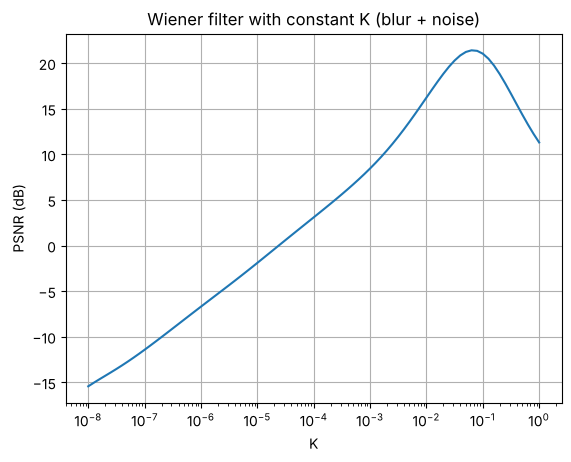

In [7]:
K_values = np.logspace(-8, 0, 81)
psnr_K = []
for K in K_values:
    psnr_K.append(r.psnr(f, r.wiener_filter(g_both, H, K)))

best_K = K_values[np.argmax(psnr_K)]
print("best K =", best_K)

plt.semilogx(K_values, psnr_K)
plt.xlabel("K")
plt.ylabel("PSNR (dB)")
plt.title("Wiener filter with constant K (blur + noise)")
plt.grid(True)
plt.show()

## 5. Wiener filter with the true spectrum
Here $S_f = |F|^2/MN$ is computed from the original image. This is not possible in practice, but it shows the best a Wiener filter can do.

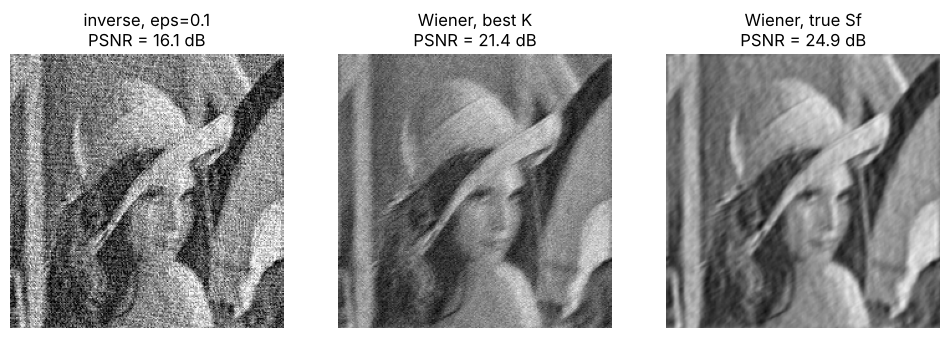

In [8]:
show(f, {"inverse, eps=0.1": r.inverse_filter(g_both, H, 0.1),
         "Wiener, best K": r.wiener_filter(g_both, H, best_K),
         "Wiener, true Sf": r.wiener_filter(g_both, H, r.true_nsr(f, SIGMA))})

## 6. Wiener filter with $\sigma$ and $S_f$ estimated from the degraded image
In practice we only have $g$ (and $h$). We estimate both unknowns from $g$.

**Noise level.** For every $2\times2$ block, $d = (a-b-c+e)/2$. Smooth image parts cancel, so $d$ is mostly noise with variance $\sigma^2$. For Gaussian noise $\mathrm{median}(|d|) = 0.6745\,\sigma$.

**Image spectrum.** Natural images have a power-law spectrum $S_f(\rho) = A/\rho^{\alpha}$, where $\rho=\sqrt{u^2+v^2}$ is the distance to frequency 0. The degraded image has $S_g = |H|^2 S_f + \sigma^2$, so $S_f = (S_g - \sigma^2)/|H|^2$. We compute that where it is reliable and fit a straight line in $\log S_f$ vs. $\log\rho$.

**Spectrum estimate.** The raw periodogram $|G|^2/MN$ is very noisy: its standard deviation is as large as its mean, whatever the image size. Averaging each value with its $5\times5$ neighbours lowers the variance about 25 times, at the cost of frequency resolution. Since we only fit 2 numbers ($A$, $\alpha$), the lower resolution does not matter.

true sigma = 10, estimated sigma = 10.17, fitted alpha = 2.63


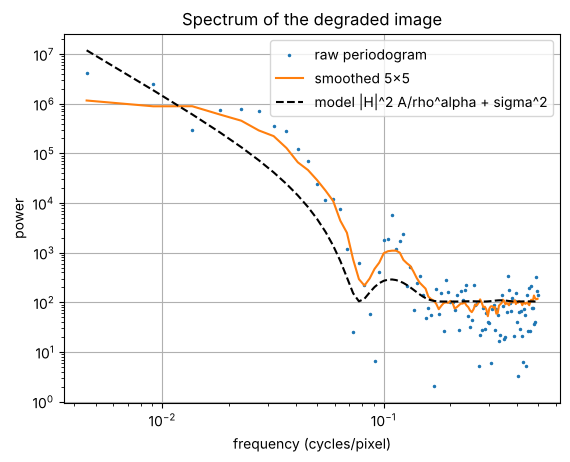

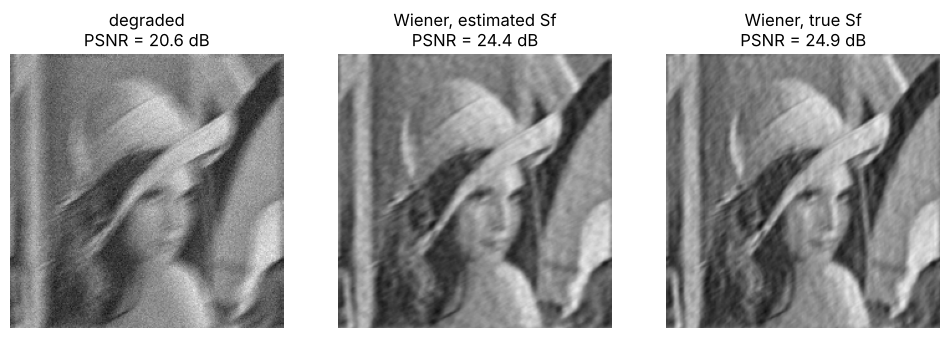

In [9]:
sigma_hat = r.estimate_sigma(g_both)
Sf_hat, alpha = r.estimate_Sf(g_both, H, sigma_hat)
print(f"true sigma = {SIGMA}, estimated sigma = {sigma_hat:.2f}, fitted alpha = {alpha:.2f}")

# Spectra along the horizontal frequency axis (first row of the DFT)
rho = r.frequency_radius(f.shape)
P_raw = r.periodogram(g_both)
P_smooth = r.smooth_periodogram(P_raw)
P_model = np.abs(H) ** 2 * Sf_hat + sigma_hat ** 2
half = f.shape[1] // 2
plt.loglog(rho[0, 1:half], P_raw[0, 1:half], ".", markersize=3, label="raw periodogram")
plt.loglog(rho[0, 1:half], P_smooth[0, 1:half], label="smoothed 5x5")
plt.loglog(rho[0, 1:half], P_model[0, 1:half], "k--", label="model |H|^2 A/rho^alpha + sigma^2")
plt.xlabel("frequency (cycles/pixel)")
plt.ylabel("power")
plt.title("Spectrum of the degraded image")
plt.legend()
plt.grid(True)
plt.show()

show(f, {"degraded": g_both,
         "Wiener, estimated Sf": r.wiener_filter(g_both, H, sigma_hat ** 2 / Sf_hat),
         "Wiener, true Sf": r.wiener_filter(g_both, H, r.true_nsr(f, SIGMA))})

## 7. Results table: all distortions, both images
For "noise only" there is no blur, so $H = 1$. The inverse filter then does nothing, and the Wiener filter becomes a pure noise filter $S_f/(S_f+S_n)$.

In [10]:
print(f"{'image':<6}{'distortion':<14}{'degraded':>9}{'inverse':>9}{'W best K':>10}{'W estim.':>10}{'W true':>8}   (PSNR in dB)")

for name in images:
    f_ = images[name]
    H_blur = np.fft.fft2(r.motion_psf(L, ANGLE, f_.shape))
    H_none = np.ones(f_.shape)

    cases = [("blur", r.blur(f_, H_blur), H_blur, 0.001),
             ("noise", r.add_noise(f_, SIGMA, rng), H_none, SIGMA),
             ("blur + noise", r.add_noise(r.blur(f_, H_blur), SIGMA, rng), H_blur, SIGMA)]

    for case, g, H_, s in cases:
        # inverse filter: tiny eps without noise, eps = 0.1 with noise
        eps = 0.001 if case == "blur" else 0.1
        f_inv = r.inverse_filter(g, H_, eps)

        # Wiener with the best constant K
        best = max(K_values, key=lambda K: r.psnr(f_, r.wiener_filter(g, H_, K)))
        f_K = r.wiener_filter(g, H_, best)

        # Wiener with sigma and Sf estimated from g
        s_hat = r.estimate_sigma(g)
        Sf_est, _ = r.estimate_Sf(g, H_, s_hat)
        f_est = r.wiener_filter(g, H_, s_hat ** 2 / Sf_est)

        # Wiener with the true spectrum
        f_true = r.wiener_filter(g, H_, r.true_nsr(f_, s))

        print(f"{name:<6}{case:<14}{r.psnr(f_, g):>9.2f}{r.psnr(f_, f_inv):>9.2f}"
              f"{r.psnr(f_, f_K):>10.2f}{r.psnr(f_, f_est):>10.2f}{r.psnr(f_, f_true):>8.2f}")

image distortion     degraded  inverse  W best K  W estim.  W true   (PSNR in dB)


I1    blur              21.43    47.98     55.25     32.59   55.26


I1    noise             28.12    28.12     28.15     31.13   32.21


I1    blur + noise      20.58    16.02     21.37     24.33   24.88


I2    blur              20.21    41.60     51.53     31.72   64.30


I2    noise             28.14    28.14     28.17     30.13   31.28


I2    blur + noise      19.56    15.85     20.47     22.43   23.04


## 8. PSNR versus noise level (blur + noise, I1)

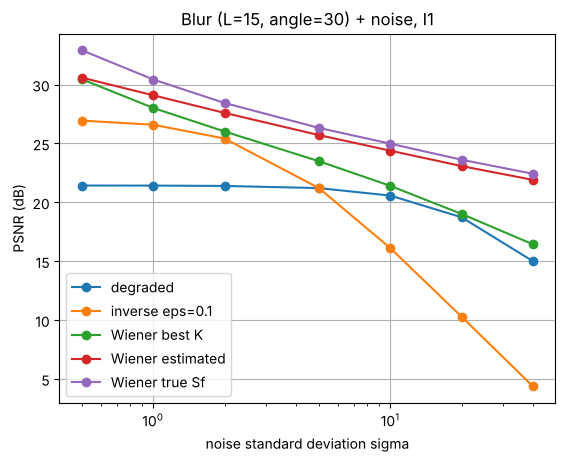

In [11]:
sigmas = [0.5, 1, 2, 5, 10, 20, 40]
curves = {"degraded": [], "inverse eps=0.1": [], "Wiener best K": [],
          "Wiener estimated": [], "Wiener true Sf": []}

for s in sigmas:
    g = r.add_noise(r.blur(f, H), s, rng)
    best = max(K_values, key=lambda K: r.psnr(f, r.wiener_filter(g, H, K)))
    s_hat = r.estimate_sigma(g)
    Sf_est, _ = r.estimate_Sf(g, H, s_hat)

    curves["degraded"].append(r.psnr(f, g))
    curves["inverse eps=0.1"].append(r.psnr(f, r.inverse_filter(g, H, 0.1)))
    curves["Wiener best K"].append(r.psnr(f, r.wiener_filter(g, H, best)))
    curves["Wiener estimated"].append(r.psnr(f, r.wiener_filter(g, H, s_hat ** 2 / Sf_est)))
    curves["Wiener true Sf"].append(r.psnr(f, r.wiener_filter(g, H, r.true_nsr(f, s))))

for label in curves:
    plt.semilogx(sigmas, curves[label], "o-", label=label)
plt.xlabel("noise standard deviation sigma")
plt.ylabel("PSNR (dB)")
plt.title(f"Blur (L={L}, angle={ANGLE}) + noise, I1")
plt.legend()
plt.grid(True)
plt.show()

**Observations.** Without noise the inverse filter (with a tiny threshold) is best. With noise it gets worse than doing nothing, because it amplifies the noise where $|H|$ is small. A constant $K$ helps only a little: it assumes a flat image spectrum, but image power drops by orders of magnitude towards high frequencies. The Wiener filter with the estimated power-law spectrum needs only $g$ and $h$, and gets within about 0.5–2 dB of the Wiener filter that knows the true spectrum.

In [12]:
# Restore g with every filter and return the PSNR of each result
def compare_filters(f, g, H, sigma):
    best_K = max(K_values, key=lambda K: r.psnr(f, r.wiener_filter(g, H, K)))
    s_hat = r.estimate_sigma(g)
    Sf_est, _ = r.estimate_Sf(g, H, s_hat)
    return {
        "degraded": r.psnr(f, g),
        "inverse eps=0.1": r.psnr(f, r.inverse_filter(g, H, 0.1)),
        "Wiener best K": r.psnr(f, r.wiener_filter(g, H, best_K)),
        "Wiener estimated": r.psnr(f, r.wiener_filter(g, H, s_hat ** 2 / Sf_est)),
        "Wiener true Sf": r.psnr(f, r.wiener_filter(g, H, r.true_nsr(f, sigma))),
    }

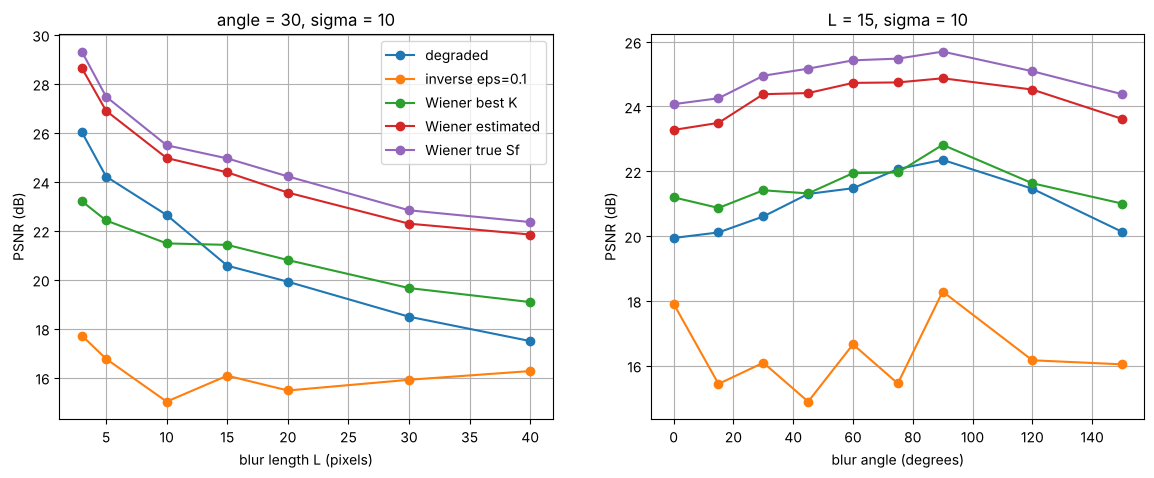

In [13]:
lengths = [3, 5, 10, 15, 20, 30, 40]
results_L = {}
for length in lengths:
    H_L = np.fft.fft2(r.motion_psf(length, ANGLE, f.shape))
    g = r.add_noise(r.blur(f, H_L), SIGMA, rng)
    results_L[length] = compare_filters(f, g, H_L, SIGMA)

angles = [0, 15, 30, 45, 60, 75, 90, 120, 150]
results_A = {}
for angle in angles:
    H_A = np.fft.fft2(r.motion_psf(L, angle, f.shape))
    g = r.add_noise(r.blur(f, H_A), SIGMA, rng)
    results_A[angle] = compare_filters(f, g, H_A, SIGMA)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for label in results_L[lengths[0]]:
    ax[0].plot(lengths, [results_L[x][label] for x in lengths], "o-", label=label)
    ax[1].plot(angles, [results_A[x][label] for x in angles], "o-", label=label)
ax[0].set_xlabel("blur length L (pixels)")
ax[0].set_title(f"angle = {ANGLE}, sigma = {SIGMA}")
ax[1].set_xlabel("blur angle (degrees)")
ax[1].set_title(f"L = {L}, sigma = {SIGMA}")
for a in ax:
    a.set_ylabel("PSNR (dB)")
    a.grid(True)
ax[0].legend()
plt.show()

In [14]:
print(f"{'L':>4}" + "".join(f"{label:>18}" for label in results_L[lengths[0]]))
for length in lengths:
    print(f"{length:>4}" + "".join(f"{v:>18.2f}" for v in results_L[length].values()))

   L          degraded   inverse eps=0.1     Wiener best K  Wiener estimated    Wiener true Sf
   3             26.02             17.72             23.20             28.64             29.31
   5             24.21             16.77             22.42             26.90             27.47
  10             22.64             15.02             21.48             24.97             25.49
  15             20.57             16.08             21.42             24.38             24.95
  20             19.92             15.47             20.80             23.56             24.22
  30             18.49             15.91             19.66             22.29             22.83
  40             17.49             16.27             19.08             21.84             22.35


**Observations.**
* The degraded image and both spectrum-based Wiener filters get worse as $L$ grows: a longer blur removes more frequencies, and no linear filter can bring those back.
* The ranking of the Wiener filters is the same for every length: true spectrum > estimated spectrum > constant $K$. For short blurs ($L \le 10$) the constant-$K$ Wiener filter and the inverse filter are even worse than doing nothing.
* The inverse filter stays around 15–18 dB for every length: with a fixed $\varepsilon = 0.1$ it is always dominated by amplified noise.
* The angle changes the results by about 2 dB. The blur removes detail in the direction of motion, so the result depends on how much detail the image has in that direction. Vertical motion (90°) does the least damage to I1, probably because it has many vertical edges (blurring along an edge barely changes it). The irregular inverse-filter curve comes from where the near-zeros of $|H|$ fall after rounding the line to pixels.

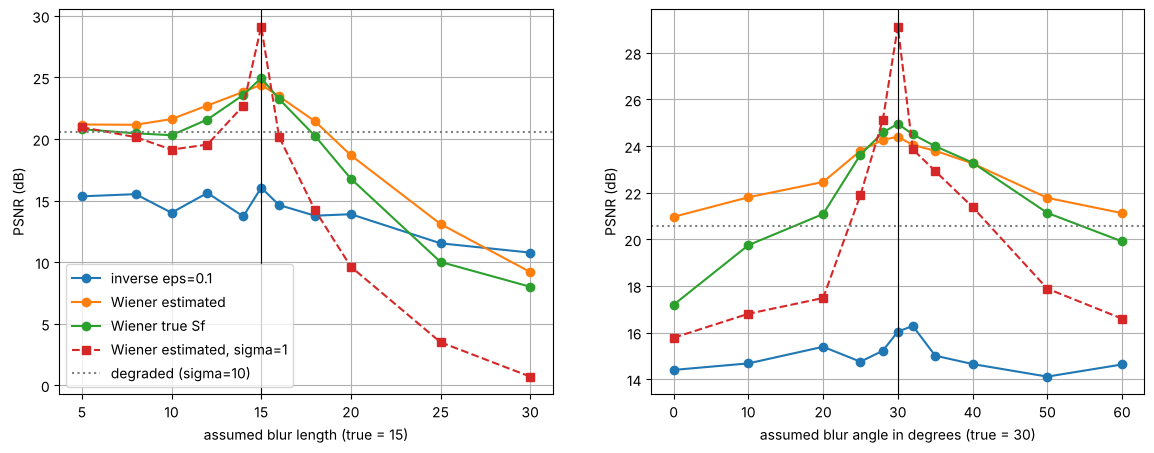

In [15]:
def restore_with_kernel(f, g, H_assumed, sigma):
    s_hat = r.estimate_sigma(g)
    Sf_est, _ = r.estimate_Sf(g, H_assumed, s_hat)
    return {
        "inverse eps=0.1": r.inverse_filter(g, H_assumed, 0.1),
        "Wiener estimated": r.wiener_filter(g, H_assumed, s_hat ** 2 / Sf_est),
        "Wiener true Sf": r.wiener_filter(g, H_assumed, r.true_nsr(f, sigma)),
    }

g_low = r.add_noise(r.blur(f, H), 1, rng)          # little noise (sigma = 1)
g_high = r.add_noise(r.blur(f, H), SIGMA, rng)     # sigma = 10

# Wrong length (angle correct)
assumed_lengths = [5, 8, 10, 12, 14, 15, 16, 18, 20, 25, 30]
psnr_wrong_L = {"inverse eps=0.1": [], "Wiener estimated": [], "Wiener true Sf": [],
                "Wiener estimated, sigma=1": []}
for length in assumed_lengths:
    H_guess = np.fft.fft2(r.motion_psf(length, ANGLE, f.shape))
    res = restore_with_kernel(f, g_high, H_guess, SIGMA)
    for label in res:
        psnr_wrong_L[label].append(r.psnr(f, res[label]))
    res_low = restore_with_kernel(f, g_low, H_guess, 1)
    psnr_wrong_L["Wiener estimated, sigma=1"].append(r.psnr(f, res_low["Wiener estimated"]))

# Wrong angle (length correct)
assumed_angles = [0, 10, 20, 25, 28, 30, 32, 35, 40, 50, 60]
psnr_wrong_A = {"inverse eps=0.1": [], "Wiener estimated": [], "Wiener true Sf": [],
                "Wiener estimated, sigma=1": []}
for angle in assumed_angles:
    H_guess = np.fft.fft2(r.motion_psf(L, angle, f.shape))
    res = restore_with_kernel(f, g_high, H_guess, SIGMA)
    for label in res:
        psnr_wrong_A[label].append(r.psnr(f, res[label]))
    res_low = restore_with_kernel(f, g_low, H_guess, 1)
    psnr_wrong_A["Wiener estimated, sigma=1"].append(r.psnr(f, res_low["Wiener estimated"]))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for label in psnr_wrong_L:
    style = "s--" if "sigma=1" in label else "o-"
    ax[0].plot(assumed_lengths, psnr_wrong_L[label], style, label=label)
    ax[1].plot(assumed_angles, psnr_wrong_A[label], style, label=label)
ax[0].axvline(L, color="k", lw=0.8)
ax[1].axvline(ANGLE, color="k", lw=0.8)
ax[0].axhline(r.psnr(f, g_high), color="gray", ls=":", label="degraded (sigma=10)")
ax[1].axhline(r.psnr(f, g_high), color="gray", ls=":")
ax[0].set_xlabel("assumed blur length (true = 15)")
ax[1].set_xlabel("assumed blur angle in degrees (true = 30)")
for a in ax:
    a.set_ylabel("PSNR (dB)")
    a.grid(True)
ax[0].legend()
plt.show()

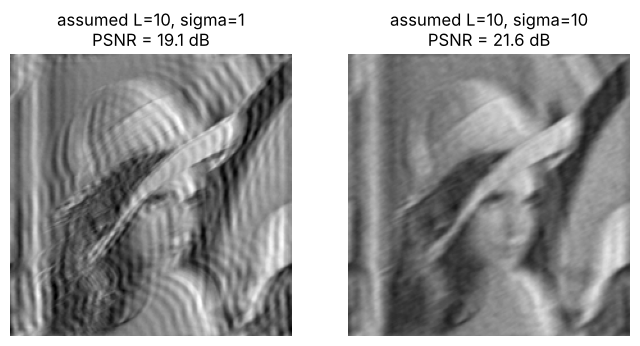

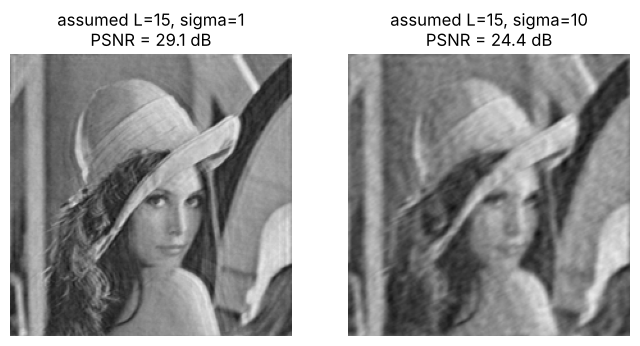

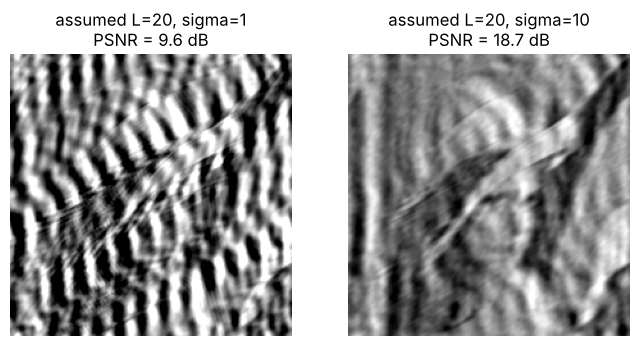

In [16]:
for length in [10, 15, 20]:
    H_guess = np.fft.fft2(r.motion_psf(length, ANGLE, f.shape))
    res = restore_with_kernel(f, g_low, H_guess, 1)
    show(f, {f"assumed L={length}, sigma=1": res["Wiener estimated"],
             f"assumed L={length}, sigma=10": restore_with_kernel(f, g_high, H_guess, SIGMA)["Wiener estimated"]})